<a href="https://colab.research.google.com/github/mertyilmaz11/IMDBPuanTahmini/blob/main/IMDBPuanTahmini.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

      YÖNETMEN OYUNU: MALİYET MENÜSÜ
--- FİLM SÜRESİ (PRODÜKSİYON ÖLÇEĞİ) ---
Kısa ( < 90 dk)          : ~ $  15,000,000
Standart (90-120 dk)     : ~ $  20,000,000
Uzun (120-150 dk)        : ~ $  38,000,000
Epik (150+ dk)           : ~ $  40,000,000
Kitap Uyarlaması Telifi: $40,500,000
Orijinal Senaryo:        $0
-------------------------
Drama Filmi Çekmek: ~ $19,400,000
Comedy Filmi Çekmek: ~ $24,000,000
Thriller Filmi Çekmek: ~ $27,000,000
Action Filmi Çekmek: ~ $42,000,000
Adventure Filmi Çekmek: ~ $55,500,000
Romance Filmi Çekmek: ~ $20,000,000
Crime Filmi Çekmek: ~ $25,000,000
Science Fiction Filmi Çekmek: ~ $40,000,000
Horror Filmi Çekmek: ~ $12,000,000
Family Filmi Çekmek: ~ $50,000,000
Fantasy Filmi Çekmek: ~ $55,000,000
Mystery Filmi Çekmek: ~ $26,500,000
Animation Filmi Çekmek: ~ $74,000,000
History Filmi Çekmek: ~ $25,000,000
War Filmi Çekmek: ~ 

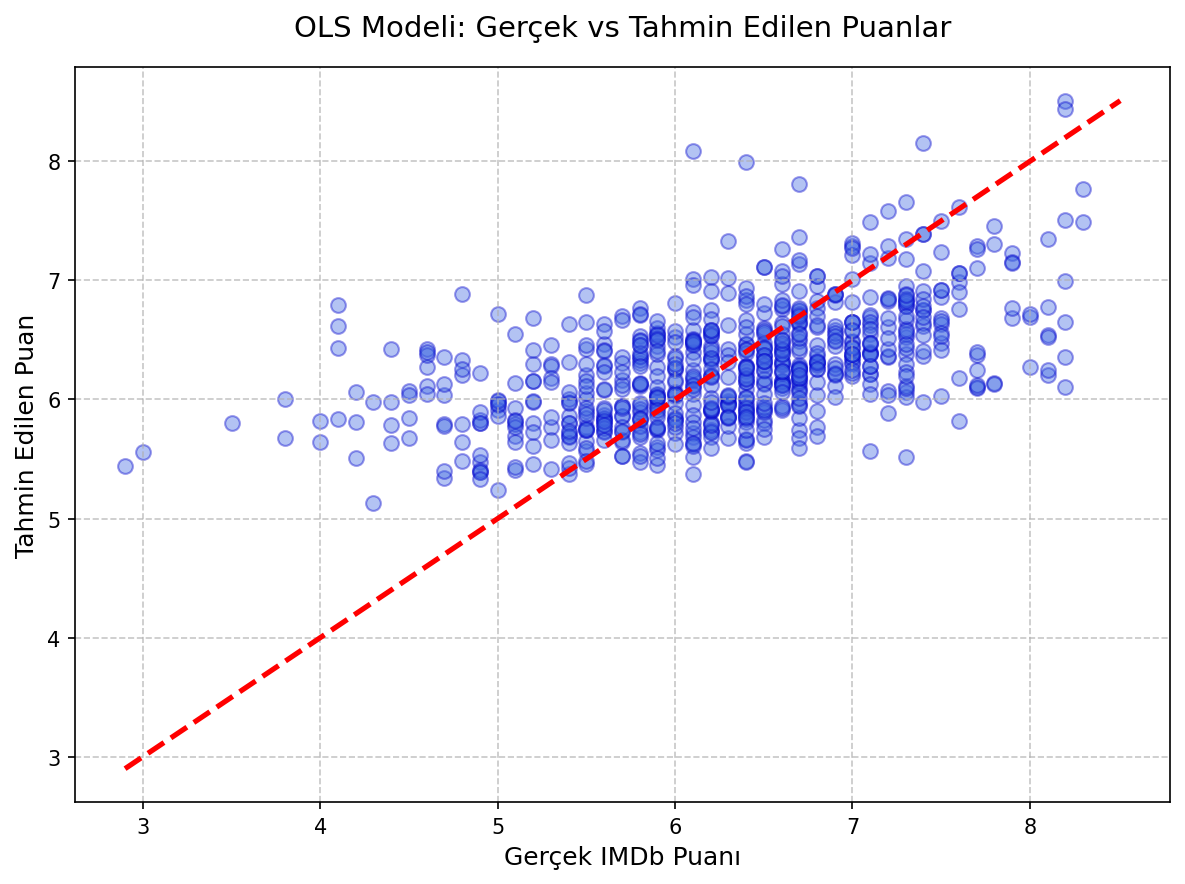


📈 Lasso Modeli Gerçek vs Tahmin grafiği çiziliyor...


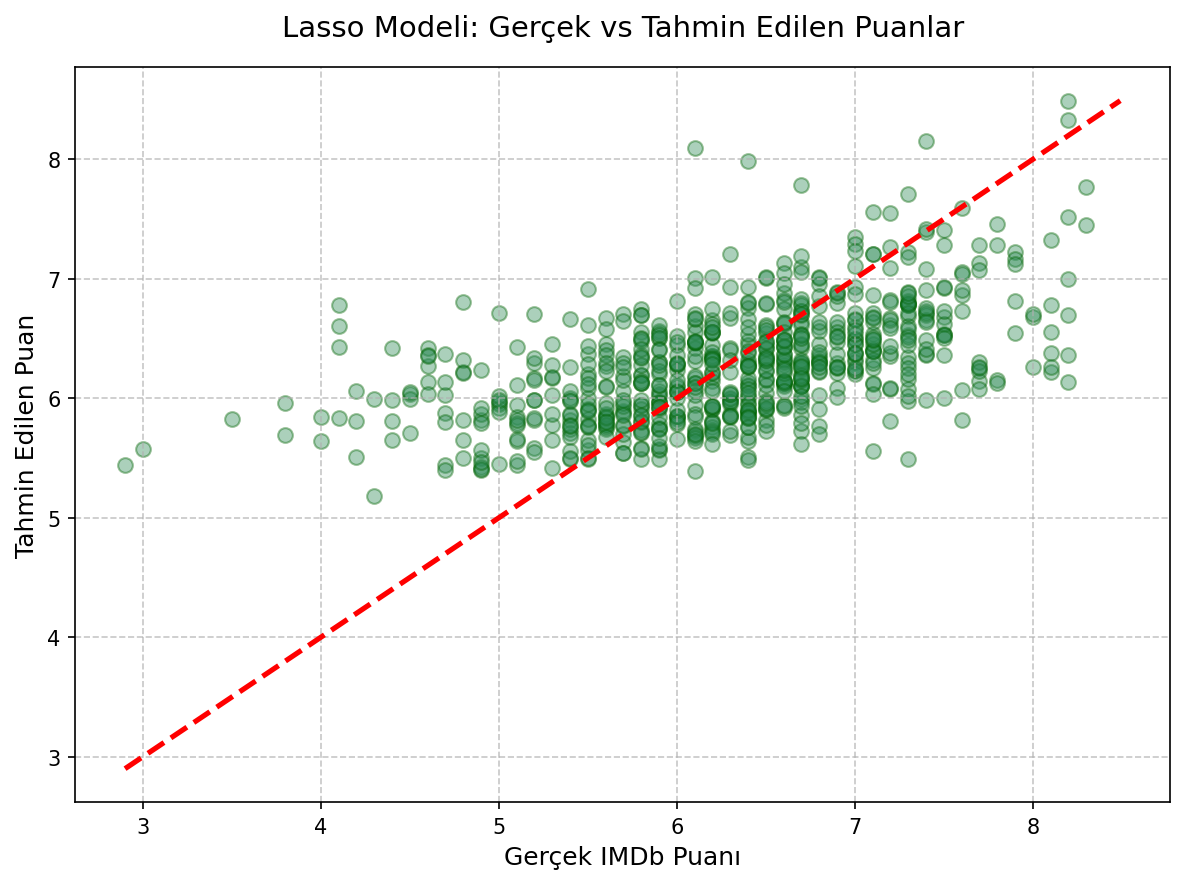


📈 RANSAC Modeli Gerçek vs Tahmin grafiği çiziliyor...


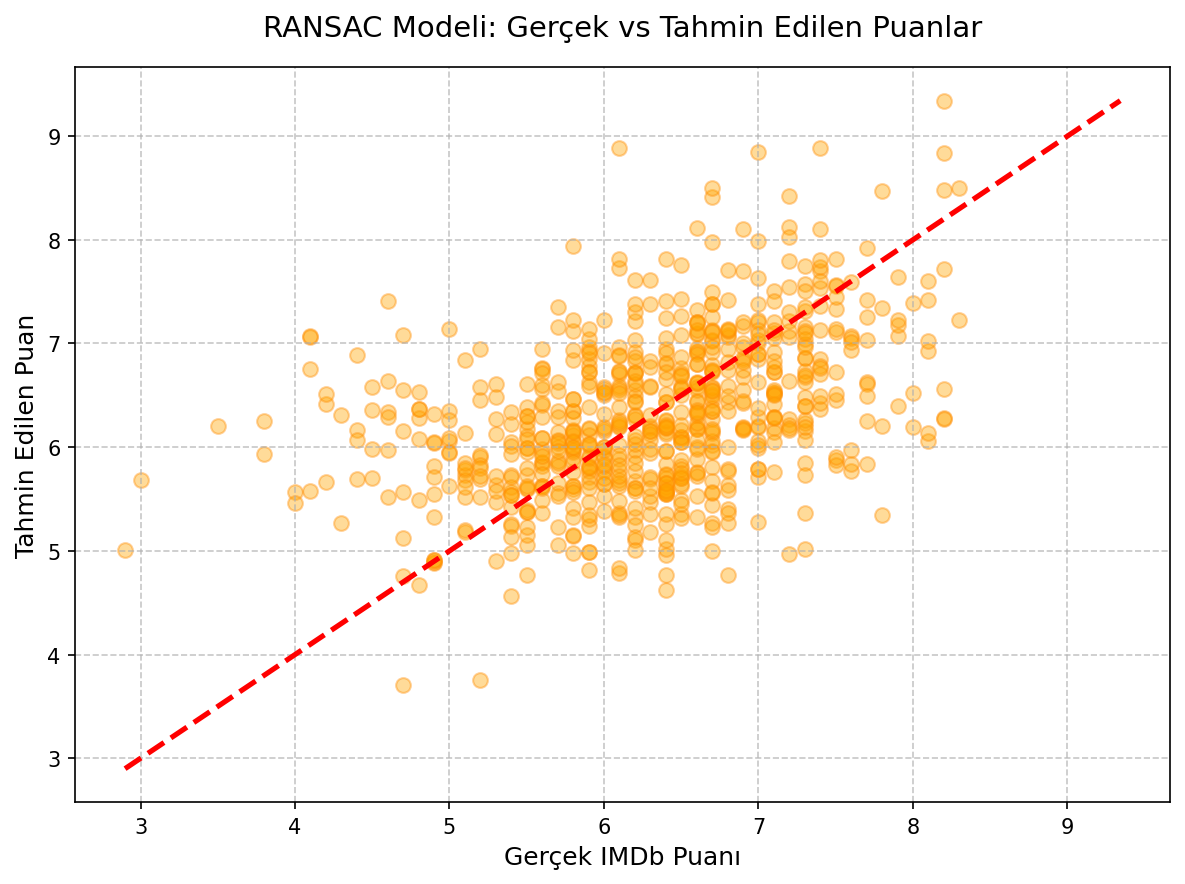


📊 Lasso Özellik Seçimi Grafiği Hazırlanıyor...
🧹 Toplam 51 özelliğin 18 tanesi elendi!


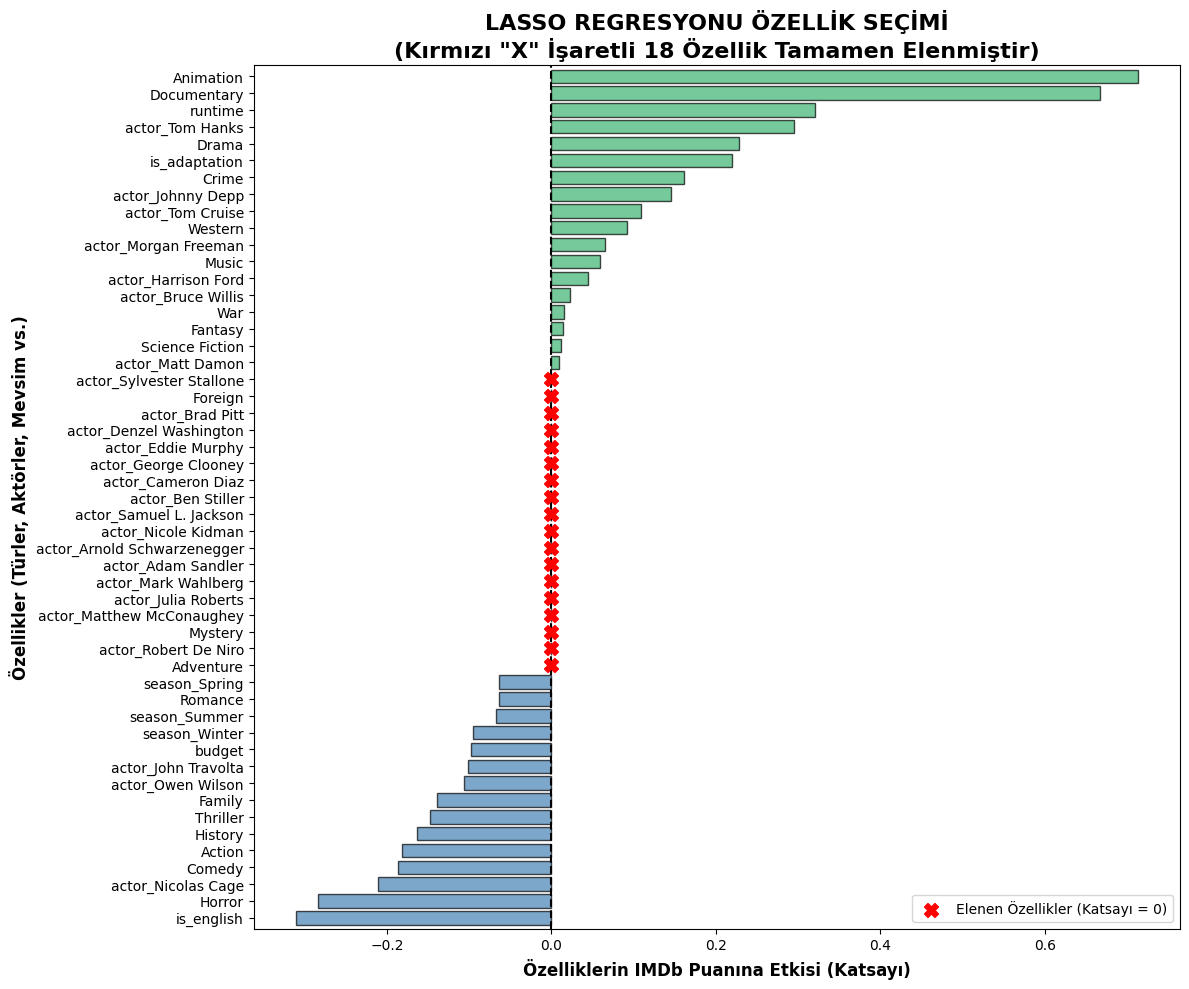


📈 Bütçe özelliğine göre model doğruları çiziliyor...
⭐ Grafiği Çizilen Özellik: budget


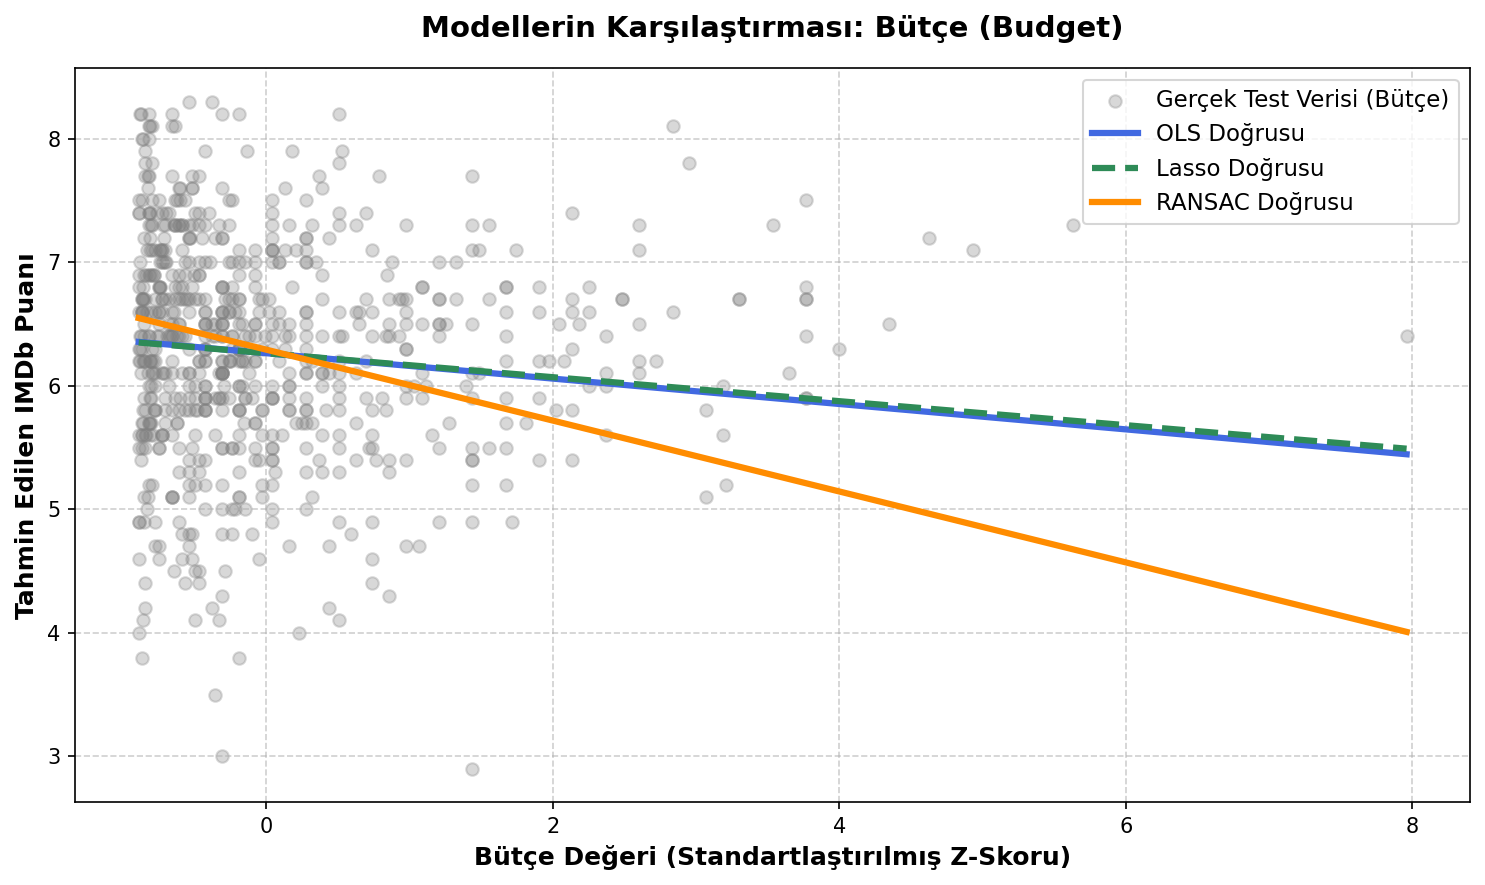


🎬 Analiz başlatılıyor...


/tmp/ipykernel_6391/2900583447.py:412: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(x='Puan', y='Yönetmen', data=lider_df, palette='magma')


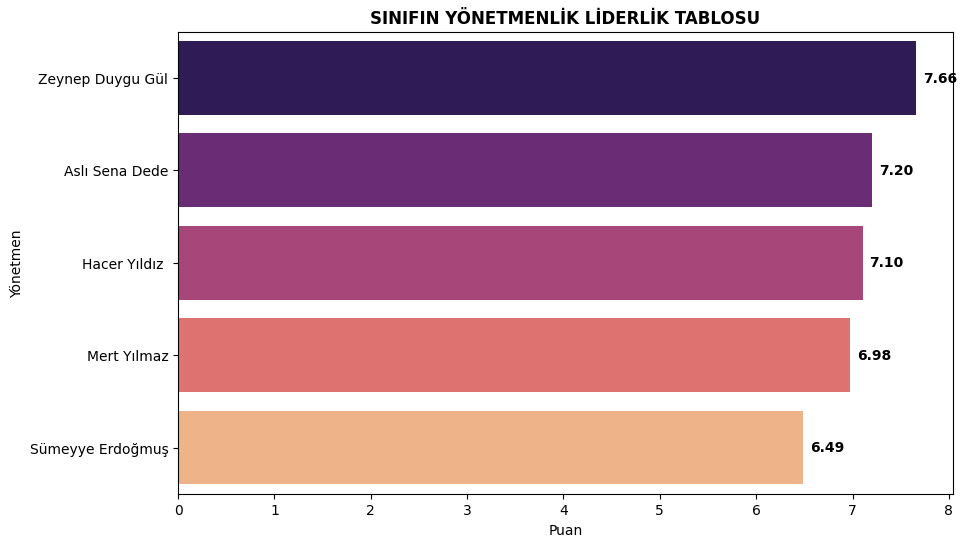

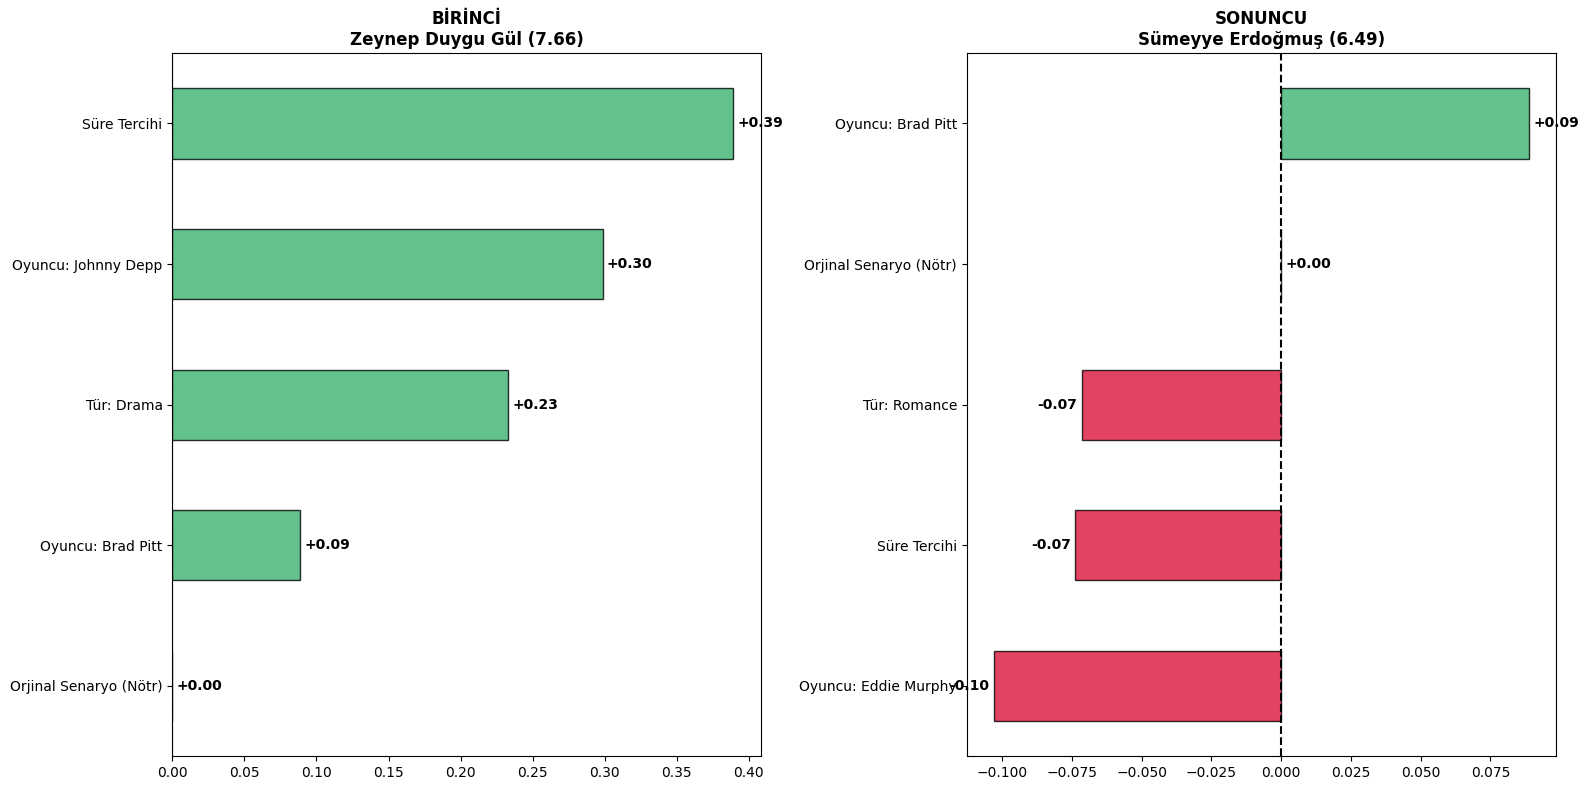

In [ ]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, LassoCV, RANSACRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ==========================================
# 1. VERİ YÜKLEME VE BİRLEŞTİRME
# ==========================================
from google.colab import drive
drive.mount('/content/drive')

# Dosyaları doğrudan Drive'dan çekiyoruz
movies = pd.read_csv('/content/drive/MyDrive/MakineÖğrenmesiProjesi/tmdb_5000_movies.csv')
credits = pd.read_csv('/content/drive/MyDrive/MakineÖğrenmesiProjesi/tmdb_5000_credits.csv')
df = movies.merge(credits, left_on='id', right_on='movie_id')

# ==========================================
# 2. TEMİZLİK VE FİLTRELEME
# ==========================================
df = df[(df['budget'] > 0) & (df['vote_count'] > 10)].copy()
df['runtime'] = df['runtime'].fillna(df['runtime'].median())

# ==========================================
# 3. ÖZNİTELİK MÜHENDİSLİĞİ
# ==========================================

# A. Mevsimler
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['month'] = df['release_date'].dt.month

def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'


df['season'] = df['month'].apply(get_season)
season_dummies = pd.get_dummies(df['season'], prefix='season', drop_first=True, dtype=int)


# B. Türler
def parse_json(x):
    try:
        return [i['name'] for i in ast.literal_eval(x)]
    except:
        return []


df['genres_list'] = df['genres'].apply(parse_json)
genre_dummies = df['genres_list'].apply(lambda x: '|'.join(x)).str.get_dummies(sep='|')

if 'TV Movie' in genre_dummies.columns:
    genre_dummies = genre_dummies.drop('TV Movie', axis=1)


# C. Kitap Uyarlaması
def check_adaptation(x):
    keywords = str(x).lower()
    if 'based on novel' in keywords or 'based on book' in keywords or 'based on comic' in keywords:
        return 1
    return 0

df['is_adaptation'] = df['keywords'].apply(check_adaptation)

# D. Dil
df['is_english'] = df['original_language'].apply(lambda x: 1 if x == 'en' else 0)

# E. Oyuncular (En Popüler 25 Başrol)
df['top_cast'] = df['cast'].apply(lambda x: [i['name'] for i in ast.literal_eval(x)[:3]] if pd.notnull(x) else [])
tum_oyuncular = df['top_cast'].explode()
en_populer_oyuncular = tum_oyuncular.value_counts().nlargest(25).index.tolist()

actor_dummies = pd.DataFrame(index=df.index)
for actor in en_populer_oyuncular:
    actor_dummies[f'actor_{actor}'] = df['top_cast'].apply(lambda x: 1 if actor in x else 0)

# ==========================================
# 4. YÖNETMEN OYUNU İÇİN FİYAT LİSTESİ
# ==========================================
print("\n" + "=" * 45)
print("      YÖNETMEN OYUNU: MALİYET MENÜSÜ")
print("=" * 45)

def runtime_category(r):
    if r < 90:
        return "Kısa ( < 90 dk)"
    elif 90 <= r <= 120:
        return "Standart (90-120 dk)"
    elif 120 < r <= 150:
        return "Uzun (120-150 dk)"
    else:
        return "Epik (150+ dk)"


df['runtime_cat'] = df['runtime'].apply(runtime_category)

print("--- FİLM SÜRESİ (PRODÜKSİYON ÖLÇEĞİ) ---")
runtime_siralamasi = ["Kısa ( < 90 dk)", "Standart (90-120 dk)", "Uzun (120-150 dk)", "Epik (150+ dk)"]
for cat in runtime_siralamasi:
    maliyet = df[df['runtime_cat'] == cat]['budget'].median()
    print(f"{cat:25}: ~ ${maliyet:12,.0f}")
print(f"Kitap Uyarlaması Telifi: ${df[df['is_adaptation'] == 1]['budget'].median():,.0f}")
print(f"Orijinal Senaryo:        $0")
print("-" * 25)

top_10_freq_genres = genre_dummies.sum().nlargest(25).index.tolist()
for tur in top_10_freq_genres:
    maliyet = df[genre_dummies[tur] == 1]['budget'].median()
    print(f"{tur} Filmi Çekmek: ~ ${maliyet:,.0f}")
print("-" * 25)

for actor in en_populer_oyuncular:
    maliyet = df[df['top_cast'].apply(lambda x: actor in x)]['budget'].median()
    print(f"{actor}: ~ ${maliyet:,.0f}")

# ==========================================
# 5. STANDARTLAŞTIRMA VE MATRİS BİRLEŞTİRME
# ==========================================
scaler = StandardScaler()
num_scaled = pd.DataFrame(scaler.fit_transform(df[['budget', 'runtime']]),
                          columns=['budget', 'runtime'], index=df.index)

X = pd.concat([num_scaled, season_dummies, genre_dummies,
               df[['is_adaptation', 'is_english']], actor_dummies], axis=1)
y = df['vote_average']

# ==========================================
# 6. MODEL EĞİTİMİ VE TEST
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


def evaluate(name, model):
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    print(f"\n--- {name} Performansı ---")
    print(f"MAE: {mean_absolute_error(y_test, preds):.4f}")
    print(f"MSE: {mean_squared_error(y_test, preds):.4f}")
    print(f"R2 : {r2_score(y_test, preds):.4f}")
    return model


ols_model = evaluate("OLS", LinearRegression())
print("\n🔍 Lasso için optimum alpha değeri hesaplanıyor (5-Fold Cross-Validation)...")
# cv=5 demek, veriyi 5 parçaya bölüp her alpha değerini 5 kere test et demektir.
lasso_cv = LassoCV(cv=5, random_state=42)
lasso_cv.fit(X_train, y_train)
optimum_alpha = lasso_cv.alpha_
print(f"✅ Bulunan Optimum Alpha (Ceza Katsayısı): {optimum_alpha:.5f}")

# Modeli bulunan bu en iyi alpha değeri ile değerlendiriyoruz
lasso_model = evaluate(f"LASSO (Alpha: {optimum_alpha:.5f})", lasso_cv)

ransac_model = evaluate("RANSAC", RANSACRegressor(random_state=42))

# ==========================================
# OLS MODELİ: GERÇEK VS TAHMİN GRAFİĞİ
# ==========================================
print("\n📈 OLS Modeli Gerçek vs Tahmin grafiği çiziliyor...")

# OLS modelinin test verisi üzerindeki tahminlerini alıyoruz
ols_preds = ols_model.predict(X_test)

# Grafik boyut ve çözünürlük ayarı
plt.figure(figsize=(8, 6), dpi=150)

# Veri noktalarını çizdirme
plt.scatter(y_test, ols_preds, alpha=0.4, c='royalblue', edgecolors='mediumblue', s=50)

# İdeal Tahmin Çizgisi
min_val = min(y_test.min(), ols_preds.min())
max_val = max(y_test.max(), ols_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2.5)

# Başlık ve eksen isimlendirmeleri
plt.title('OLS Modeli: Gerçek vs Tahmin Edilen Puanlar', fontsize=14, pad=15)
plt.xlabel('Gerçek IMDb Puanı', fontsize=12)
plt.ylabel('Tahmin Edilen Puan', fontsize=12)

# Arka plan ızgarası (Grid)
plt.grid(True, linestyle='--', alpha=0.7)

# Düzenleme ve gösterme
plt.tight_layout()
plt.show()

# ==========================================
# LASSO MODELİ: GERÇEK VS TAHMİN GRAFİĞİ
# ==========================================
print("\n📈 Lasso Modeli Gerçek vs Tahmin grafiği çiziliyor...")

# Lasso modelinin tahminleri
lasso_preds = lasso_model.predict(X_test)

plt.figure(figsize=(8, 6), dpi=150)

# Veri noktaları
plt.scatter(y_test, lasso_preds, alpha=0.4, c='seagreen', edgecolors='darkgreen', s=50)

# İdeal Tahmin Çizgisi
min_val_lasso = min(y_test.min(), lasso_preds.min())
max_val_lasso = max(y_test.max(), lasso_preds.max())
plt.plot([min_val_lasso, max_val_lasso], [min_val_lasso, max_val_lasso], color='red', linestyle='--', linewidth=2.5)

plt.title('Lasso Modeli: Gerçek vs Tahmin Edilen Puanlar', fontsize=14, pad=15)
plt.xlabel('Gerçek IMDb Puanı', fontsize=12)
plt.ylabel('Tahmin Edilen Puan', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# ==========================================
# RANSAC MODELİ: GERÇEK VS TAHMİN GRAFİĞİ
# ==========================================
print("\n📈 RANSAC Modeli Gerçek vs Tahmin grafiği çiziliyor...")

# RANSAC modelinin tahminleri
ransac_preds = ransac_model.predict(X_test)

plt.figure(figsize=(8, 6), dpi=150)

# Veri noktaları
plt.scatter(y_test, ransac_preds, alpha=0.4, c='orange', edgecolors='darkorange', s=50)

# İdeal Tahmin Çizgisi
min_val_ran = min(y_test.min(), ransac_preds.min())
max_val_ran = max(y_test.max(), ransac_preds.max())
plt.plot([min_val_ran, max_val_ran], [min_val_ran, max_val_ran], color='red', linestyle='--', linewidth=2.5)

plt.title('RANSAC Modeli: Gerçek vs Tahmin Edilen Puanlar', fontsize=14, pad=15)
plt.xlabel('Gerçek IMDb Puanı', fontsize=12)
plt.ylabel('Tahmin Edilen Puan', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# ==========================================
# 7. LASSO ÖZELLİK SEÇİMİ (FEATURE SELECTION) GÖRSELLEŞTİRMESİ
# ==========================================
print("\n📊 Lasso Özellik Seçimi Grafiği Hazırlanıyor...")

# Lasso modelinin katsayılarını ve sütun isimlerini alıyoruz
lasso_katsayilar = pd.Series(lasso_model.coef_, index=X.columns)

# Sıfır olanlar
elenen_sayisi = (lasso_katsayilar == 0).sum()
print(f"🧹 Toplam {len(X.columns)} özelliğin {elenen_sayisi} tanesi elendi!")

plt.figure(figsize=(12, 10))

# Katsayıları sıralıyoruz
sirali_katsayilar = lasso_katsayilar.sort_values()

# Renk paleti
renkler = ['lightgray' if val == 0 else ('mediumseagreen' if val > 0 else 'steelblue') for val in sirali_katsayilar]

# Bar grafiğini çiz
ax = sirali_katsayilar.plot(kind='barh', color=renkler, width=0.8, edgecolor='black', alpha=0.7)

# Değeri 0 olanların Y eksenindeki yerlerini (koordinatlarını) bul
y_koordinatlari = np.where(sirali_katsayilar == 0)[0]
# O noktalara X=0 hizasında kırmızı çarpı ekle
ax.scatter([0]*len(y_koordinatlari), y_koordinatlari, color='red', marker='X', s=100, label='Elenen Özellikler (Katsayı = 0)', zorder=5)

plt.title(f'LASSO REGRESYONU ÖZELLİK SEÇİMİ\n(Kırmızı "X" İşaretli {elenen_sayisi} Özellik Tamamen Elenmiştir)', fontsize=16, weight='bold')
plt.xlabel('Özelliklerin IMDb Puanına Etkisi (Katsayı)', fontsize=12, weight='bold')
plt.ylabel('Özellikler (Türler, Aktörler, Mevsim vs.)', fontsize=12, weight='bold')

# Tam sıfır noktasına belirgin bir kesik çizgi çekelim
plt.axvline(0, color='black', linewidth=1.5, linestyle='--')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# ==========================================
# BÜTÇE ÖZELLİĞİNE GÖRE MODEL DOĞRULARI
# ==========================================
print("\n📈 Bütçe özelliğine göre model doğruları çiziliyor...")

# 1. Özelliği 'budget' olarak manuel belirliyoruz
en_onemli_ozellik = 'budget'
print(f"⭐ Grafiği Çizilen Özellik: {en_onemli_ozellik}")

# 2. X ekseninde göstermek için bu özelliğin test setindeki min ve max değerlerini alalım
x_gercek = X_test[en_onemli_ozellik].values
x_line = np.linspace(x_gercek.min(), x_gercek.max(), 100)

# 3. Sentetik bir veri seti oluşturalım (Diğer tüm değişkenler ortalama değerde sabitlenecek)
X_sentetik = pd.DataFrame(np.zeros((100, X.shape[1])), columns=X.columns)

for col in X.columns:
    X_sentetik[col] = X_train[col].mean() # Diğer her şey ortalama bir film gibi

# Sadece 'budget' özelliğimizi min'den max'a doğru değiştiriyoruz
X_sentetik[en_onemli_ozellik] = x_line

# 4. Modellerin bu sentetik veri üzerindeki tahminleri (Çizgilerimiz)
y_ols_line = ols_model.predict(X_sentetik)
y_lasso_line = lasso_model.predict(X_sentetik)
y_ransac_line = ransac_model.predict(X_sentetik)

# 5. Grafik Çizimi
plt.figure(figsize=(10, 6), dpi=150)

# Arka plana test verisinin gerçek dağılımını soluk olarak ekleyelim
plt.scatter(x_gercek, y_test, alpha=0.3, color='gray', label='Gerçek Test Verisi (Bütçe)')

# Model Doğruları
plt.plot(x_line, y_ols_line, color='royalblue', linewidth=3, label='OLS Doğrusu')
plt.plot(x_line, y_lasso_line, color='seagreen', linewidth=3, linestyle='--', label='Lasso Doğrusu')
plt.plot(x_line, y_ransac_line, color='darkorange', linewidth=3, label='RANSAC Doğrusu')

# Tasarım ayarları
plt.title('Modellerin Karşılaştırması: Bütçe (Budget)', fontsize=14, pad=15, weight='bold')
plt.xlabel('Bütçe Değeri (Standartlaştırılmış Z-Skoru)', fontsize=12, weight='bold')
plt.ylabel('Tahmin Edilen IMDb Puanı', fontsize=12, weight='bold')

plt.legend(loc='best', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# ==========================================
# 8. YÖNETMEN OYUNU SİMÜLASYONU
# ==========================================
def final_simulasyonu_baslat(csv_dosyasi):
    print("\n🎬 Analiz başlatılıyor...")

    try:
        yanitlar = pd.read_csv('/content/drive/MyDrive/MakineÖğrenmesiProjesi/form.csv')
        sonuclar = []
        aktif_model = ols_model
        katsayilar = pd.Series(aktif_model.coef_, index=X.columns)
        taban_puan = aktif_model.intercept_

        for index, row in yanitlar.iterrows():
            girdi = pd.DataFrame(0, index=[0], columns=X.columns)

            # 1. SÜRE
            r_q = 'Kaç dakikalık bir film çekmek istersiniz?'
            if r_q in row:
                r_text = str(row[r_q])
                if '90' in r_text and '120' in r_text:
                    sure = 105.0
                elif '120' in r_text and '150' in r_text:
                    sure = 135.0
                elif '150' in r_text:
                    sure = 160.0
                else:
                    sure = 95.0
                sc_input = pd.DataFrame([[50000000, sure]], columns=['budget', 'runtime'])
                sc = scaler.transform(sc_input)
                girdi['runtime'] = sc[0][1]

            # 2. SENARYO
            s_q = 'Senaryo tipi nasıl olsun? '
            if s_q in row:
                s_text = str(row[s_q]).lower()
                if 'uyarlama' in s_text or 'kitap' in s_text or 'adaptation' in s_text:
                    girdi['is_adaptation'] = 1

            # 3. TÜRLER (PARANTEZ TEMİZLEME EKLENDİ)
            t_q = 'Film türü ne olsun? '
            secilen_turler = []
            if t_q in row and str(row[t_q]) != 'nan':
                # Örn: "Action (Aksiyon), Drama (Dram)" gelirse virgülle ayırır
                ham_cevaplar = [s.strip() for s in str(row[t_q]).split(',')]

                for cevap in ham_cevaplar:
                    # "Action (Aksiyon)" metnini "(" karakterinden böler ve sadece "Action" kısmını alır
                    temiz_cevap = cevap.split('(')[0].strip()

                    if temiz_cevap in girdi.columns:
                        girdi[temiz_cevap] = 1
                        secilen_turler.append(temiz_cevap)

            # 4. AKTÖRLER
            secilen_aktorler = []
            for a_q in ['Çalışmak istediğiniz 1. aktör kim?', 'Çalışmak istediğiniz 2. aktör kim?']:
                if a_q in row:
                    a_text = str(row[a_q])
                    if a_text != 'nan' and 'Hiçbiri' not in a_text and 'None' not in a_text:
                        a_isim = a_text.split('(')[0].strip()
                        s_adi = f"actor_{a_isim}"
                        if s_adi in girdi.columns:
                            girdi[s_adi] = 1
                            secilen_aktorler.append(a_isim)

            tahmin = taban_puan + (girdi.iloc[0] * katsayilar).sum()
            yonetmen = row.get('İsim Soyisim', f"Yönetmen {index + 1}")

            sonuclar.append({
                'Yönetmen': yonetmen, 'Puan': tahmin, 'Girdi': girdi,
                'Türler': secilen_turler, 'Aktörler': secilen_aktorler
            })

        # --- GRAFİKLER ---
        lider_df = pd.DataFrame(sonuclar).sort_values(by='Puan', ascending=False)
        plt.figure(figsize=(10, 6));
        ax1 = sns.barplot(x='Puan', y='Yönetmen', data=lider_df, palette='magma')
        for c in ax1.containers: ax1.bar_label(c, fmt='%.2f', padding=5, weight='bold')
        plt.title('SINIFIN YÖNETMENLİK LİDERLİK TABLOSU', weight='bold');
        plt.show()

        en_iyi = next(i for i in sonuclar if i['Yönetmen'] == lider_df.iloc[0]['Yönetmen'])
        en_kotu = next(i for i in sonuclar if i['Yönetmen'] == lider_df.iloc[-1]['Yönetmen'])
        fig, axes = plt.subplots(1, 2, figsize=(16, 8))

        def analiz_ciz(data, unvan, ax):
            g = data['Girdi']
            k = (g.iloc[0] * katsayilar).copy()
            if g.iloc[0]['is_adaptation'] == 0: k['is_adaptation'] = 0.0001
            for t in data['Türler']:
                if k[t] == 0: k[t] = 0.0001

            k = k[k != 0].drop(['budget', 'is_english'], errors='ignore').sort_values()

            etiketler = []
            for idx in k.index:
                if idx.startswith('actor_'):
                    etiketler.append(f"Oyuncu: {idx.replace('actor_', '')}")
                elif idx == 'runtime':
                    etiketler.append('Süre Tercihi')
                elif idx == 'is_adaptation':
                    etiketler.append('Kitap Uyarlama' if g.iloc[0][idx] == 1 else 'Orjinal Senaryo (Nötr)')
                else:
                    etiketler.append(f"Tür: {idx}" + (" (Nötr)" if abs(k[idx]) <= 0.0001 else ""))

            k.index = etiketler
            colors = ['lightgray' if 'Nötr' in n else ('crimson' if v < 0 else 'mediumseagreen') for v, n in
                      zip(k.values, k.index)]
            k.plot(kind='barh', ax=ax, color=colors, edgecolor='black', alpha=0.8)
            ax.set_title(f"{unvan}\n{data['Yönetmen']} ({data['Puan']:.2f})", weight='bold')
            ax.axvline(0, color='black', lw=1.5, ls='--')
            for c in ax.containers: ax.bar_label(c, fmt='%+.2f', padding=3, weight='bold')

        analiz_ciz(en_iyi, "BİRİNCİ", axes[0])
        analiz_ciz(en_kotu, "SONUNCU", axes[1])
        plt.tight_layout();
        plt.show()

    except Exception as e:
        print(f"❌ HATA: {e}")

final_simulasyonu_baslat('/content/drive/MyDrive/MakineÖğrenmesiProjesi/form.csv')